Objetivo: Entrenar un modelo neuronal con capas lineales (MLP) para que aprenda a reconstruir una imagen (el dibujo de Shin Chan)1.Resolución de trabajo: Para simplificar la práctica, la imagen se reducirá inicialmente a un tamaño de $35 \times 30$ píxeles1.Concepto: Una imagen son colores asociados a una posición $(x, y) \longrightarrow (R, G, B)$2. El modelo debe reproducir la imagen sin necesitar el archivo original una vez entrenado2.Codificación Posicional (Positional Encoding): Como los MLPs tienen dificultades para aprender cambios bruscos de color (variaciones de alta frecuencia), se debe transformar la entrada $(x, y)$ usando funciones trigonométricas (seno y coseno) a distintas frecuencias mediante la clase Positional_Encoder (con $L=10$ y include_input=True)2more_horiz.Upscaling: Una vez entrenado el MLP, se requiere utilizarlo para generar la imagen al doble de resolución ($70 \times 60$)4.

In [15]:
import torch

print("PyTorch:", torch.__version__)

# Mini test de memoria y tensor en tu RTX 5060
x = torch.randn(10, 10, device="cuda")
print("CUDA OK:", (x @ x).is_cuda)

PyTorch: 2.11.0+cu128
CUDA OK: True


In [16]:
import math
import torch
import torch.nn as nn


class Positional_Encoder(nn.Module):
    def __init__(self, L=10, include_input=True, device='cpu'):
        super(Positional_Encoder, self).__init__()
        self.include_input = include_input
        self.device = device
        self.freq_bands = 2.0 ** torch.linspace(0.0, L - 1, L, device=self.device)

    def forward(self, x):
        out = [x] if self.include_input else []
        for freq in self.freq_bands:
            out.append(torch.sin(freq * x * math.pi))
            out.append(torch.cos(freq * x * math.pi))
        return torch.cat(out, dim=-1)

    def get_output_dim(self, input_dim):
        return (input_dim if self.include_input else 0) + 2 * input_dim * len(self.freq_bands)

Tensor Image shape: torch.Size([3, 30, 35])
Colors shape: torch.Size([1050, 3])
Tamaño coordenadas: torch.Size([1050, 2])


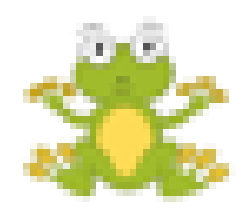

In [17]:
from PIL import Image
import torch
from torchvision import transforms
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

width, height = 35, 30  

# 1. Cargar y redimensionar imagen en PIL: espera (width, height)
image_pil = Image.open("frog_png.jpg").convert("RGB")
image_pil = image_pil.resize((width, height))

# 2. Convertir a tensor -> shape: [3, height, width] = [3, 30, 35]
transform = transforms.ToTensor()
image = transform(image_pil)
print(f"Tensor Image shape: {image.shape}")

# 3. Colores ordenados: [height, width, 3] -> [1050, 3]
# El recorrido fila por fila (flatten) sigue primero height (Y) y luego width (X)
colors = image.permute(1, 2, 0).reshape(-1, 3)
print(f"Colors shape: {colors.shape}")

# 4. Coordenadas: y tiene 'height' pasos (30), x tiene 'width' pasos (35)
y = torch.linspace(0, 1, steps=height)
x = torch.linspace(0, 1, steps=width)

# Con indexing='ij', la primera matriz es Y (filas) y la segunda X (columnas)
grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')

# Apilar [Y, X] o [X, Y]. Si mantienes [Y, X], mantén el mismo orden al evaluar:
coordinates = torch.stack([grid_y.flatten(), grid_x.flatten()], dim=1)
print(f"Tamaño coordenadas: {coordinates.shape}")

# 5. Visualizar original
plt.figure(figsize=(3, 3))
plt.imshow(image.permute(1, 2, 0))
plt.axis("off")
plt.show()

In [18]:
dataset = TensorDataset(coordinates, colors)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

In [19]:
class ImageMLP(nn.Module):
    def __init__(self, in_features=42, hidden_features=256, out_features=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, out_features),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [20]:
encoder = Positional_Encoder(L=10, include_input=True)
sample_coords = torch.rand(256, 2)
print("Salida encoder:", encoder(sample_coords).shape)
# Debería imprimir exactamente: torch.Size([256, 42])

Salida encoder: torch.Size([256, 42])


Época [ 100/1000] - Loss MSE: 0.000537
Época [ 200/1000] - Loss MSE: 0.000096
Época [ 300/1000] - Loss MSE: 0.000044
Época [ 400/1000] - Loss MSE: 0.000011
Época [ 500/1000] - Loss MSE: 0.000009
Época [ 600/1000] - Loss MSE: 0.000051
Época [ 700/1000] - Loss MSE: 0.000004
Época [ 800/1000] - Loss MSE: 0.000042
Época [ 900/1000] - Loss MSE: 0.000002
Época [1000/1000] - Loss MSE: 0.000062


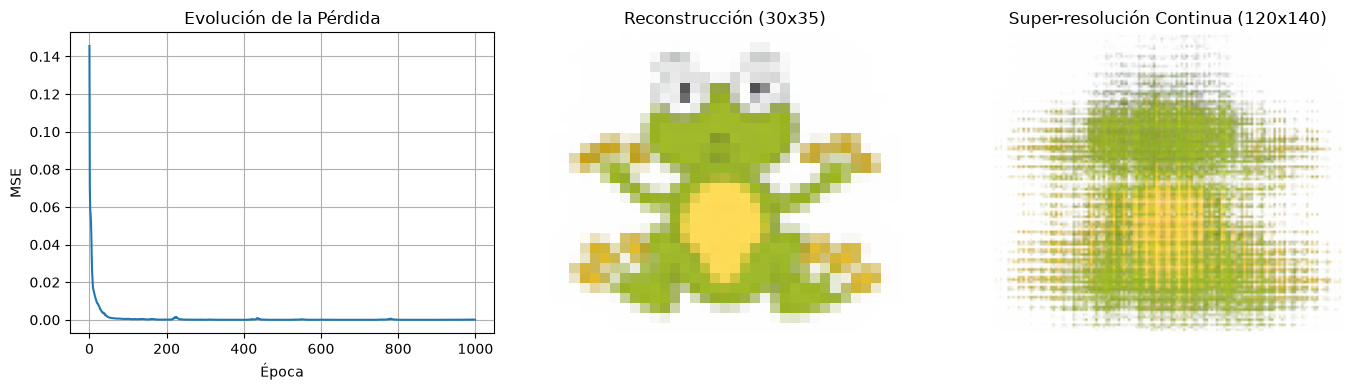

In [21]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Configuración de ejecución
device = torch.device("cuda")
model = ImageMLP().to(device)
encoder = encoder.to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 1000
loss_history = []

# 2. Bucle de entrenamiento (100% de los datos)
for epoch in range(epochs):
    model.train()
    total_epoch_loss = 0.0

    for coords_batch, colors_batch in dataloader:
        coords_batch = coords_batch.to(device)
        colors_batch = colors_batch.to(device)

        # Paso hacia adelante
        encoded_coords = encoder(coords_batch)
        predictions = model(encoded_coords)
        loss = loss_fn(predictions, colors_batch)

        # Retropropagación y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_epoch_loss += loss.item() * coords_batch.size(0)

    epoch_loss = total_epoch_loss / len(dataloader.dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 100 == 0:
        print(f"Época [{epoch+1:4d}/{epochs}] - Loss MSE: {epoch_loss:.6f}")

# 3. Evaluación y Reconstrucción
model.eval()
with torch.no_grad():
    coords_eval = coordinates.to(device)
    encoded_eval = encoder(coords_eval)
    predicted_colors = model(encoded_eval)

# height=30 (filas), width=35 (columnas)
h_orig, w_orig = height, width
recon_img = predicted_colors.cpu().reshape(h_orig, w_orig, 3).numpy().clip(0, 1)

# 4. Upscaling continuo (4x: 120x140)
scale = 4
h_up, w_up = h_orig * scale, w_orig * scale

y_up = torch.linspace(0, 1, steps=h_up)
x_up = torch.linspace(0, 1, steps=w_up)
grid_y_up, grid_x_up = torch.meshgrid(y_up, x_up, indexing='ij')
coords_up = torch.stack([grid_y_up.flatten(), grid_x_up.flatten()], dim=1).to(device)

with torch.no_grad():
    encoded_up = encoder(coords_up)
    predicted_up = model(encoded_up)
    upscaled_img = predicted_up.cpu().reshape(h_up, w_up, 3).numpy().clip(0, 1)

# 5. Visualización de resultados
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.title("Evolución de la Pérdida")
plt.plot(loss_history)
plt.xlabel("Época")
plt.ylabel("MSE")
plt.grid(True)

plt.subplot(1, 3, 2)
plt.title(f"Reconstrucción ({h_orig}x{w_orig})")
plt.imshow(recon_img)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title(f"Super-resolución Continua ({h_up}x{w_up})")
plt.imshow(upscaled_img)
plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
for coords_batch, colors_batch in dataloader:
    print("1. coords_batch entrada:", coords_batch.shape)
    enc = encoder(coords_batch)
    print("2. encoder(coords_batch) salida:", enc.shape)
    print("3. model capa 1 espera:", model.fc1.weight.shape if hasattr(model, 'fc1') else "Revisa model")
    break

1. coords_batch entrada: torch.Size([256, 2])
2. encoder(coords_batch) salida: torch.Size([256, 42])
3. model capa 1 espera: Revisa model
